<a href="https://colab.research.google.com/github/Muhammadjon1211/computer_vision/blob/master/pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

In [2]:
print(torch.__version__)

2.11.0+cu130


In [5]:
print("CUDA available:", torch.cuda.is_available())

CUDA available: True


In [17]:
scalar = torch.tensor(5) #0d
print(scalar)
print("shape:", scalar.shape)
print("number of dimensions:", scalar.ndim)
print("size:", scalar.size())

tensor(5)
shape: torch.Size([])
number of dimensions: 0
size: torch.Size([])


In [16]:
vector = torch.tensor([1,2,3]) #1d
print("vector:", vector)
print("shape:", vector.shape)
print("number of dimensions:", vector.ndim)
print("size:", vector.size())

vector: tensor([1, 2, 3])
shape: torch.Size([3])
number of dimensions: 1
size: torch.Size([3])


In [18]:
MATRIX = torch.tensor([[1,2,3], [4,5,6]]) #2d Shape
print("matrix:", MATRIX)
print("shape:", MATRIX.shape)
print("number of dimensions:", MATRIX.ndim)
print("size:", MATRIX.size())

matrix: tensor([[1, 2, 3],
        [4, 5, 6]])
shape: torch.Size([2, 3])
number of dimensions: 2
size: torch.Size([2, 3])


In [19]:
tensor3d = torch.stack([MATRIX, MATRIX+10])
print('tensor3d:', tensor3d)
print("shape:", tensor3d.shape)
print("number of dimensions:", tensor3d.ndim)
print("size:", tensor3d.size())

tensor3d: tensor([[[ 1,  2,  3],
         [ 4,  5,  6]],

        [[11, 12, 13],
         [14, 15, 16]]])
shape: torch.Size([2, 2, 3])
number of dimensions: 3
size: torch.Size([2, 2, 3])


In [26]:
random_number = torch.rand(3,3)
print("random_number:", random_number)
print("shape:", random_number.shape)
print("number of dimensions:", random_number.ndim)
print("size:", random_number.size())
print("dtype:", random_number.dtype)
print("device:", random_number.device)

random_number: tensor([[0.9182, 0.8682, 0.1216],
        [0.7232, 0.9623, 0.2988],
        [0.9247, 0.7128, 0.6477]])
shape: torch.Size([3, 3])
number of dimensions: 2
size: torch.Size([3, 3])
dtype: torch.float32
device: cpu


In [22]:
print("zeros:", torch.zeros(3,3))

zeros: tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])


In [23]:
print("ones:", torch.ones(2,3))

ones: tensor([[1., 1., 1.],
        [1., 1., 1.]])


In [33]:
x = torch.tensor([[1,2],
                 [3,4]])

y = torch.tensor([[5,6],
                 [7,8]])

#Element wise-addition
print("Addition:", x+y)
print("================================")

#Element wise-multiplicaiton
print("Multiplicaiton:", x*y)
print("================================")

#Matrix-multiplicaiton
print("Matrix @ multiplication:", x@y)
print("================================")

#print("Matrix @ multiplication:", torch.matmul(x,y))
#print("================================")

Addition: tensor([[ 6,  8],
        [10, 12]])
Multiplicaiton: tensor([[ 5, 12],
        [21, 32]])
Matrix @ multiplication: tensor([[19, 22],
        [43, 50]])
Matrix @ multiplication: tensor([[19, 22],
        [43, 50]])


# Neural Network

In [34]:
from torch import nn
import matplotlib.pyplot as plt

In [35]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [36]:
weight = 0.7
bias = 0.3

start = 0
end = 1
step = 0.02

X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

train_split = int(0.8 * len(X))

X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

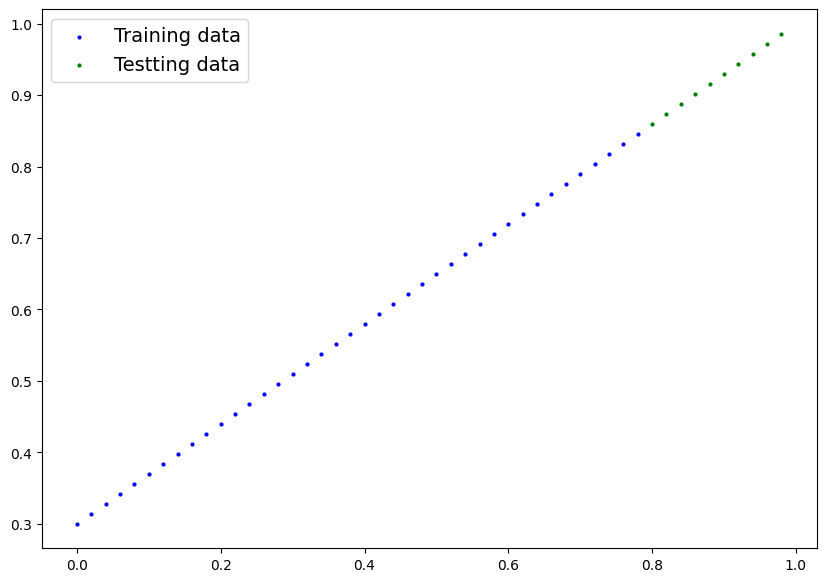

In [39]:
def plot_predictions(train_data=X_train,
                    train_labels=y_train,
                    test_data=X_test,
                    test_labels=y_test,
                    predictions=None):
  plt.figure(figsize=(10,7))
  #train
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")
  #test
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testting data")

  if predictions is not None:
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  plt.legend(prop={"size":14})

plot_predictions()

In [40]:
class LinearRegressionModelV2(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear_layer = nn.Linear(in_features=1,
                                  out_features=1)

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return self.linear_layer(x)

torch.manual_seed(42)

model_1 = LinearRegressionModelV2()
model_1, model_1.state_dict()

(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [41]:
loss_fn = nn.L1Loss() #qanchalik yomon ishlayotkanini korish Loss function | MAE Mean Absolute Error
optimizer = torch.optim.SGD(params=model_1.parameters(),
                            lr=0.01)

Text(0.5, 1.0, 'Predictions before training(red = random guesses)')

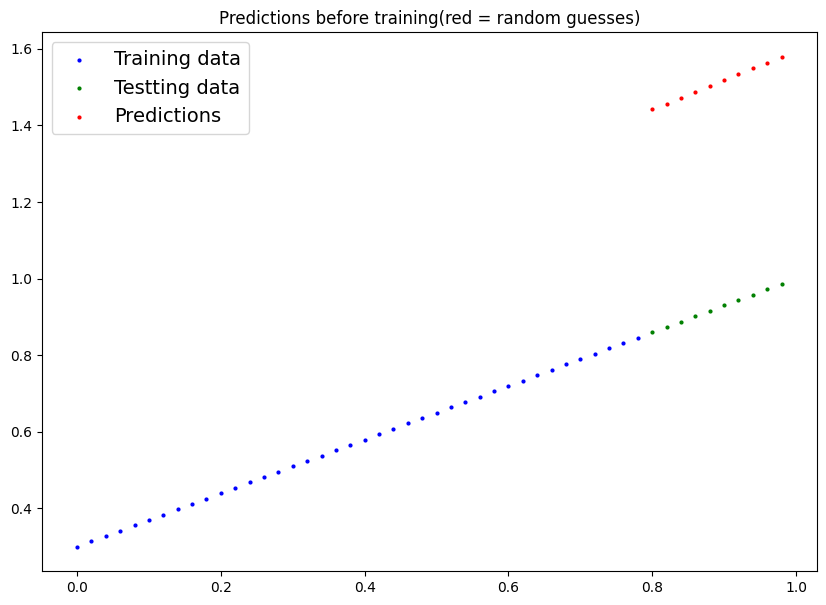

In [43]:
model_1.eval()
with torch.inference_mode():
  preds = model_1(X_test)

plot_predictions(predictions=preds)
plt.title("Predictions before training(red = random guesses)")

In [45]:
epochs = 1000

# Put model on target device
model_1.to(device)

X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

for epoch in range(epochs):
  model_1.train()

  y_pred = model_1(X_train)

  loss = loss_fn(y_pred, y_train)

  optimizer.zero_grad()

  loss.backward()

  optimizer.step()

  model_1.eval()

  with torch.inference_mode():
    test_pred = model_1(X_test)
    test_loss = loss_fn(test_pred, y_test)

  if epoch % 100 == 0:
    print(f"Epoch: {epoch} | Train loss: {loss} | Test loss: {test_loss}")

Epoch: 0 | Train loss: 0.5551779270172119 | Test loss: 0.5739762187004089
Epoch: 100 | Train loss: 0.006215683650225401 | Test loss: 0.014086711220443249
Epoch: 200 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 300 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 400 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 500 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 600 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 700 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 800 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 900 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882


In [47]:
model_1.eval()

with torch.inference_mode():
  y_preds = model_1(X_test)
y_preds

tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]], device='cuda:0')

TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.

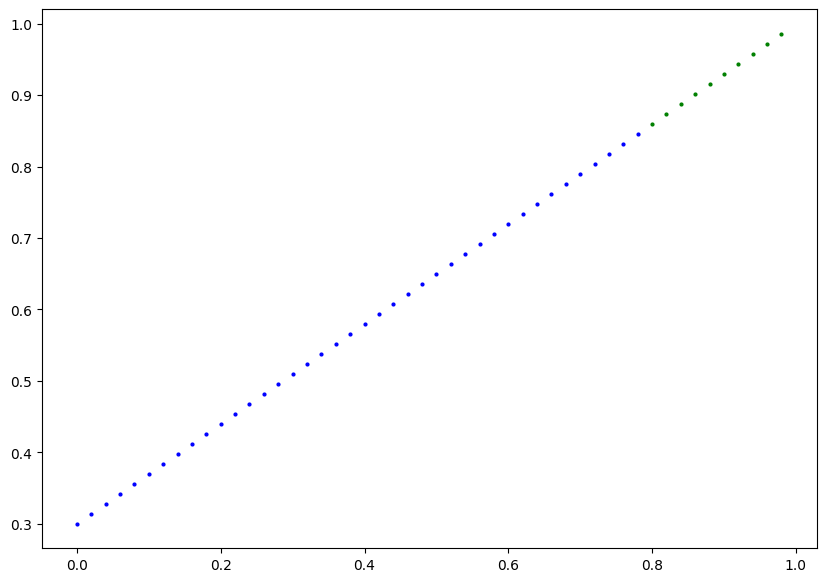

In [49]:
plot_predictions(predictions=y_preds)
plt.show()

In [50]:
torch.save(model_1.state_dict(), "linear_regression_model.pth")

In [52]:
loaded_model = LinearRegressionModelV2()
loaded_model.load_state_dict(torch.load("linear_regression_model.pth"))

loaded_model.eval()

LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)